# Lead-lag design for a normalized camera axis

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/blob/main/laboratories/08-camera-compensation/notebook.ipynb)

## Goal
For $G(s)=1/[s(s+1)]$, design lead compensation with crossover $\omega_c=3\,\mathrm{rad/s}$ and target phase margin $55^\circ$, centering maximum lead at crossover. Add lag zero $0.03\,\mathrm{rad/s}$ and pole $0.006\,\mathrm{rad/s}$, then renormalize gain at $\omega_c$. Compare final phase margins, velocity constants $K_v$, ramp errors and reference responses.

**Evidence:** every parameter and dataset is synthetic and was chosen for this original teaching scenario.

## Start from the physical system

![Physical system](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/main/laboratories/08-camera-compensation/figures/physical-system.png)

A camera gimbal illustrates angular tracking and disturbance rejection. Its normalized plant is stipulated, with no claim that geometry alone determines its two poles.

[Five integrated practice problems](https://github.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/blob/main/laboratories/08-camera-compensation/exercises.pdf) accompany this model.

The equipment view includes state and unit labels, governing balances and interpretation limits. [Vector PDF](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/main/laboratories/08-camera-compensation/figures/physical-system.pdf) · [Editable TikZ](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/main/laboratories/08-camera-compensation/figures/physical-system.tikz).


## Read the system diagram

![System diagram](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/main/laboratories/08-camera-compensation/figures/system-diagram.png)

Lead and lag sections are drawn separately so their gain normalization and frequency ordering can be analyzed independently.

The diagram is original TikZ artwork; the numerical records below are synthetic.

## Setup
Run the optional installation cell if packages are missing. No private data, supplied PDFs or external model files are required.

In [ ]:
%pip -q install numpy scipy matplotlib control

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import control as ct
from scipy.integrate import solve_ivp
from scipy.optimize import brentq, least_squares
plt.ioff()
plt.rcParams.update({'figure.figsize': (9,4.5), 'font.size': 10, 'axes.grid': True, 'grid.alpha': .25})


## Derive the model
### Lead synthesis
At $\omega_c=3$, the plant phase is $-90^\circ-\tan^{-1}(3)$. Required additional phase is $\phi=55^\circ-180^\circ-\angle G(j3)$, a positive value less than 90 degrees. For

$$
C_a=K\frac{Ts+1}{\alpha Ts+1},\quad \alpha=\frac{1-\sin\phi}{1+\sin\phi},\quad T=\frac1{\omega_c\sqrt\alpha},
$$

the maximum phase lead occurs at the prescribed crossover. Its magnitude there is $K/\sqrt\alpha$, giving $K=\sqrt\alpha/|G(j\omega_c)|$.
### Lag extension
Use $C_b=(1+s/0.03)/(1+s/0.006)$. Its DC gain is one and high-frequency gain is 0.2. Renormalize with $\gamma=1/|C_a(j3)C_b(j3)G(j3)|$. The combined controller is $\gamma C_aC_b$.
The lag decreases the margin slightly; it does not preserve the lead-only margin exactly. Because its corner frequencies are far below crossover, the reduction is small while the low-frequency loop gain rises by approximately five.
### Ramp accuracy
For this type-one plant, $K_v=\lim_{s\to0}sC(s)G(s)=C(0)$ and the unit-ramp error is $1/K_v$, provided the closed loop is stable. Reference-step final values remain one, so a step alone cannot reveal the improvement in ramp accuracy.
### Tradeoffs
The slower lag dynamics can extend settling and store controller state. This normalized exercise does not include actuator saturation, camera inertia units, backlash or sensor noise; the controller is not a hardware calibration.

## Compute and check
The first lines declare the scenario parameters. Follow the model construction, run the numerical experiment, and inspect the assertions and printed metrics.

In [2]:
plant=ct.tf([1],[1,1,0]); crossover=3.; desired_margin=55.
phase=np.angle(ct.evalfr(plant,1j*crossover),deg=True)
needed=np.radians(desired_margin-180-phase)
alpha=(1-np.sin(needed))/(1+np.sin(needed))
lead_time=1/(crossover*np.sqrt(alpha)); gain=np.sqrt(alpha)/abs(ct.evalfr(plant,1j*crossover))
lead=ct.tf(gain*np.array([lead_time,1]),[alpha*lead_time,1])
lag=ct.tf([1/.03,1],[1/.006,1])
scale=1/abs(ct.evalfr(lead*lag*plant,1j*crossover))
controllers=[('Lead',lead),('Lead + lag',scale*lead*lag)]
time=np.linspace(0,160,16001); responses=[]
for label,controller in controllers:
    closed=ct.feedback(controller*plant,1)
    margin=ct.margin(controller*plant)[1]; kv=float(ct.dcgain(controller))
    assert np.all(ct.poles(closed).real<0)
    _,step=ct.step_response(closed,time)
    ramp=ct.forced_response(closed,time,time).outputs
    responses.append((label,step,time-ramp))
    print(f'{label}: phase margin={margin:.6f} deg, Kv={kv:.6f}, limiting unit-ramp error={1/kv:.6f}')
assert abs(ct.margin(lead*plant)[1]-55)<1e-7
assert 54 < ct.margin(scale*lead*lag*plant)[1] <55
assert 4.9 < float(ct.dcgain(scale*lead*lag)/ct.dcgain(lead)) <5.1


Lead: phase margin=55.000000 deg, Kv=4.775006, limiting unit-ramp error=0.209424


Lead + lag: phase margin=54.541653 deg, Kv=23.873883, limiting unit-ramp error=0.041887


## Plot the evidence
The figure below displays the computed experiment. Axis units and legends distinguish the model variants; the curves are simulations.

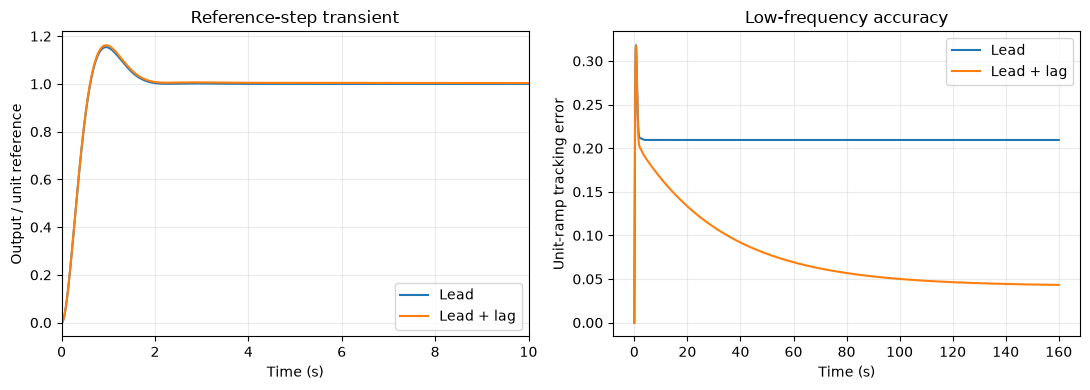

In [3]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
for label,step,error in responses:
    axes[0].plot(time,step,label=label); axes[1].plot(time,error,label=label)
axes[0].set(xlabel='Time (s)',ylabel='Output / unit reference',title='Reference-step transient',xlim=(0,10))
axes[1].set(xlabel='Time (s)',ylabel='Unit-ramp tracking error',title='Low-frequency accuracy')
for ax in axes: ax.legend()
fig.tight_layout()

plt.show()

## Interpret and extend
A meaningful compensation comparison needs both stability margin and low-frequency accuracy. Keep the slow lag transient visible when interpreting ramp error.

Change one parameter at a time, predict the direction of its effect from the equations, and rerun all cells. Explain any discrepancy before accepting a revised conclusion.

## References
- [APMonitor Dynamics and Control](https://apmonitor.com/pdc/)
- [Feedback Systems, open textbook](https://fbsbook.org/)
- [Python Control documentation](https://python-control.readthedocs.io/en/0.10.2/)
- [Worked PDF report](report.pdf)